# 02 · Análisis frecuentista del experimento

**Objetivo:** estimar el efecto de cada campaña (email para hombres y email para mujeres) sobre la conversión, la visita y el gasto, siguiendo el plan de análisis del notebook 01, y evaluar cuánto de lo observado podría deberse al azar.

**Conceptos que se usan**
- **Diferencia absoluta:** tasa del grupo menos tasa del control, en puntos porcentuales (pp). Si una tasa pasara de 1 % a 1,5 %, la diferencia absoluta sería 0,5 pp.
- **Aumento relativo (lift):** cuánto crece la tasa respecto del control. En el ejemplo anterior, 50 %. Se calcula con la razón de tasas: una razón de 1,5 equivale a un aumento relativo de 50 %.
- **Intervalo de confianza (IC) del 95 %:** rango de valores del efecto compatibles con los datos. Si no incluye el 0, la diferencia es estadísticamente significativa al 5 %. Su ancho muestra qué tan precisa es la estimación.
- **P-valor:** probabilidad de observar una diferencia al menos así de grande si la campaña no tuviera ningún efecto. No mide la probabilidad de que la campaña funcione ni qué tan grande es el efecto.
- **Corrección de Holm:** al hacer varias comparaciones, aumenta la chance de encontrar "algo significativo" por azar. Holm ajusta los p-valores para controlar ese riesgo, y es menos conservador que Bonferroni.
- **Bootstrap:** método que simula repetir el experimento remuestreando los datos con reemplazo. Sirve para estimar intervalos de confianza cuando la distribución es muy asimétrica, como la del gasto.

**Comparaciones:** hombres vs. control, mujeres vs. control y hombres vs. mujeres. Dentro de cada métrica, la corrección de Holm se aplica sobre las tres.

## 1. Setup y datos

Se importan las librerías, las funciones estadísticas de `src/ab.py` y la carga de datos de `src/data.py`. Se fija la semilla (42) para que el bootstrap sea reproducible.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import load_hillstrom, prepare, GRUPOS
from src.ab import (
    compare_proportions, holm_adjust, bootstrap_means, welch_diff,
    n_per_group, mde_two_props,
)

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 110

df = prepare(load_hillstrom())
n_grupo = df["grupo"].value_counts().reindex(GRUPOS)
print("Clientes por grupo:", n_grupo.to_dict())

COMPARACIONES = [("hombres", "control"), ("mujeres", "control"), ("hombres", "mujeres")]
ETIQUETA = {c: f"{c[0]} − {c[1]}" for c in COMPARACIONES}

Clientes por grupo: {'control': 21306, 'hombres': 21307, 'mujeres': 21387}


## 2. Prueba global

Antes de comparar grupos de a pares, una prueba chi-cuadrado sobre los tres grupos a la vez responde si **alguna** diferencia entre las tasas de los grupos es compatible con el azar. Si la prueba global no detectara nada, no tendría sentido buscar diferencias de a pares.

In [2]:
for metrica in ["conversion", "visit"]:
    tabla = pd.crosstab(df["grupo"], df[metrica])
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    print(f"{metrica:>10}: chi-cuadrado = {chi2:.2f} | gl = {gl} | p = {p:.3g}")

conversion: chi-cuadrado = 55.26 | gl = 2 | p = 1e-12
     visit: chi-cuadrado = 504.46 | gl = 2 | p = 2.87e-110


## 3. Conversión (métrica principal)

Para cada comparación se reporta la diferencia absoluta con su IC (método de Newcombe, basado en intervalos de Wilson, que funciona mejor que la fórmula simple cuando la tasa es baja), el aumento relativo con su IC (en escala logarítmica), el p-valor de una prueba z de dos proporciones y el p-valor ajustado por Holm.

In [3]:
def tabla_proporciones(metrica):
    x = df.groupby("grupo", observed=True)[metrica].sum()
    n = df.groupby("grupo", observed=True)[metrica].size()
    filas = []
    for a, b in COMPARACIONES:
        r = compare_proportions(int(x[a]), int(n[a]), int(x[b]), int(n[b]))
        filas.append({
            "métrica": metrica,
            "comparación": ETIQUETA[(a, b)],
            "tasa_a_%": 100 * r["p1"],
            "tasa_b_%": 100 * r["p0"],
            "dif_pp": 100 * r["diff"],
            "ic_bajo_pp": 100 * r["ic_bajo"],
            "ic_alto_pp": 100 * r["ic_alto"],
            "aumento_rel_%": 100 * (r["rr"] - 1),
            "rel_bajo_%": 100 * (r["rr_bajo"] - 1),
            "rel_alto_%": 100 * (r["rr_alto"] - 1),
            "p_valor": r["p_valor"],
        })
    t = pd.DataFrame(filas)
    t["p_holm"] = holm_adjust(t["p_valor"])
    return t

def forest(t, titulo, unidad="pp"):
    fig, ax = plt.subplots(figsize=(7, 2.6))
    y = np.arange(len(t))[::-1]
    ax.errorbar(t["dif_pp"], y, xerr=[t["dif_pp"] - t["ic_bajo_pp"], t["ic_alto_pp"] - t["dif_pp"]],
                fmt="o", capsize=4)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t["comparación"])
    ax.set_xlabel(f"Diferencia ({unidad}) con IC 95 %")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

t_conv = tabla_proporciones("conversion")
t_conv.round(5)

,métrica,comparación,tasa_a_%,tasa_b_%,dif_pp,ic_bajo_pp,ic_alto_pp,aumento_rel_%,rel_bajo_%,rel_alto_%,p_valor,p_holm
0,conversion,hombres − control,1.25311,0.57261,0.68050,0.50143,0.86407,118.84219,76.79841,170.88424,0.00000,0.00000
1,conversion,mujeres − control,0.88371,0.57261,0.31111,0.15017,0.47455,54.33130,23.01052,93.62694,0.00016,0.00031
2,conversion,hombres − mujeres,1.25311,0.88371,0.36939,0.17463,0.56626,41.80026,17.81015,70.67555,0.00021,0.00031


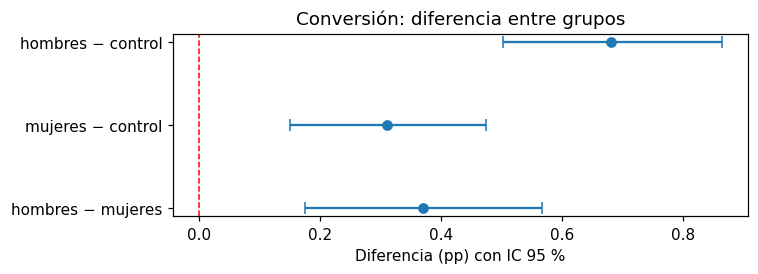

In [4]:
forest(t_conv, "Conversión: diferencia entre grupos")

**Cómo leer la tabla:** `tasa_a_%` y `tasa_b_%` son las tasas de conversión de los dos grupos comparados (el primero menos el segundo); `dif_pp` es la diferencia absoluta en puntos porcentuales y `aumento_rel_%` el aumento relativo, cada uno con su intervalo de confianza. `p_holm` es el p-valor ajustado por las tres comparaciones.

## 4. Visita al sitio (métrica secundaria)

El mismo análisis para la visita. Esta métrica es más frecuente que la compra, por lo que las estimaciones son más precisas, pero es un paso intermedio: visitar el sitio no equivale a generar ingresos.

In [5]:
t_visit = tabla_proporciones("visit")
t_visit.round(5)

,métrica,comparación,tasa_a_%,tasa_b_%,dif_pp,ic_bajo_pp,ic_alto_pp,aumento_rel_%,rel_bajo_%,rel_alto_%,p_valor,p_holm
0,visit,hombres − control,18.27568,10.61673,7.65896,6.99533,8.32267,72.14046,64.03849,80.64260,0.0,0.0
1,visit,mujeres − control,15.14004,10.61673,4.52331,3.88941,5.15743,42.60551,35.61712,49.95400,0.0,0.0
2,visit,hombres − mujeres,18.27568,15.14004,3.13565,2.42841,3.84277,20.71095,15.67909,25.96169,0.0,0.0


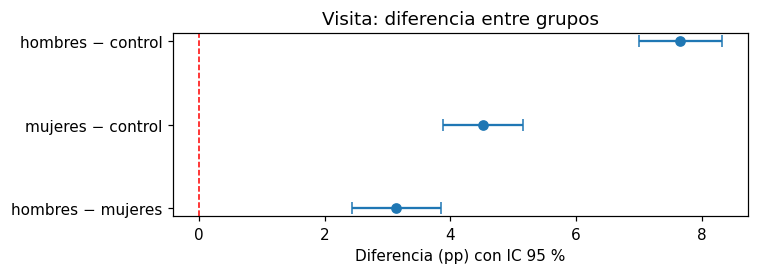

In [6]:
forest(t_visit, "Visita: diferencia entre grupos")

## 5. Gasto por cliente (métrica secundaria)

El gasto por cliente incluye a quienes no compraron (gasto cero) y es la medida del valor económico de la campaña: la diferencia de medias entre un grupo y el control es el **ingreso incremental por cliente** que recibió el email.

Como el 99 % de los clientes tiene gasto cero y entre quienes compran hay una cola larga de montos altos, la distribución está lejos de ser normal. Por eso, además de la prueba t de Welch (que compara medias sin suponer varianzas iguales), se calcula un **intervalo de confianza por bootstrap** (10.000 remuestreos), que no depende de la normalidad. El p-valor sale de la prueba de Welch, y los intervalos, del bootstrap.

In [7]:
N_BOOT = 10_000
gasto = {g: df.loc[df.grupo == g, "spend"].to_numpy() for g in GRUPOS}
medias_boot = {g: bootstrap_means(gasto[g], N_BOOT, rng) for g in GRUPOS}

filas = []
for a, b in COMPARACIONES:
    w = welch_diff(gasto[a], gasto[b])
    d_boot = medias_boot[a] - medias_boot[b]
    lo, hi = np.percentile(d_boot, [2.5, 97.5])
    filas.append({
        "métrica": "spend",
        "comparación": ETIQUETA[(a, b)],
        "media_a_USD": gasto[a].mean(),
        "media_b_USD": gasto[b].mean(),
        "dif_USD": w["diff"],
        "ic_boot_bajo": lo,
        "ic_boot_alto": hi,
        "ic_welch_bajo": w["ic_bajo"],
        "ic_welch_alto": w["ic_alto"],
        "p_valor": w["p_valor"],
    })
t_gasto = pd.DataFrame(filas)
t_gasto["p_holm"] = holm_adjust(t_gasto["p_valor"])
t_gasto.round(4)

,métrica,comparación,media_a_USD,media_b_USD,dif_USD,ic_boot_bajo,ic_boot_alto,ic_welch_bajo,ic_welch_alto,p_valor,p_holm
0,spend,hombres − control,1.4226,0.6528,0.7698,0.4822,1.0580,0.4851,1.0545,0.0000,0.0000
1,spend,mujeres − control,1.0772,0.6528,0.4244,0.1747,0.6853,0.1690,0.6799,0.0011,0.0023
2,spend,hombres − mujeres,1.4226,1.0772,0.3454,0.0348,0.6582,0.0326,0.6583,0.0305,0.0305


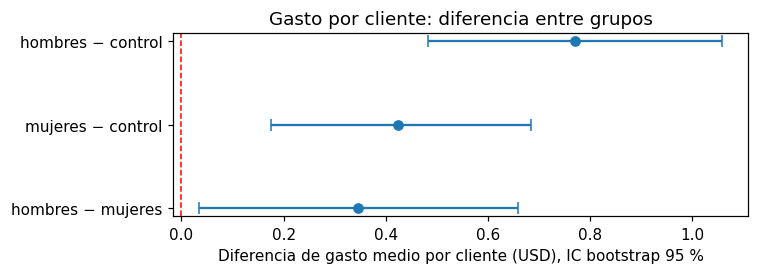

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(t_gasto))[::-1]
ax.errorbar(t_gasto["dif_USD"], y,
            xerr=[t_gasto["dif_USD"] - t_gasto["ic_boot_bajo"], t_gasto["ic_boot_alto"] - t_gasto["dif_USD"]],
            fmt="o", capsize=4)
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(t_gasto["comparación"])
ax.set_xlabel("Diferencia de gasto medio por cliente (USD), IC bootstrap 95 %")
ax.set_title("Gasto por cliente: diferencia entre grupos")
plt.tight_layout()
plt.show()

### 5.1 Ingreso incremental por cada 1.000 emails

Traducción a términos de negocio: la diferencia de gasto medio frente al control, multiplicada por 1.000 clientes. Es **ingreso bruto**: no descuenta el costo del email ni el margen de los productos (el dataset no trae esos datos).

In [9]:
incremental = t_gasto[t_gasto["comparación"].str.endswith("control")][
    ["comparación", "dif_USD", "ic_boot_bajo", "ic_boot_alto"]
].copy()
for c in ["dif_USD", "ic_boot_bajo", "ic_boot_alto"]:
    incremental[c] = incremental[c] * 1000
incremental.columns = ["comparación", "ingreso_incremental_por_1000_USD", "ic_bajo", "ic_alto"]
incremental.round(1)

,comparación,ingreso_incremental_por_1000_USD,ic_bajo,ic_alto
0,hombres − control,769.8,482.2,1058.0
1,mujeres − control,424.4,174.7,685.3


### 5.2 Sensibilidad a los montos altos

Unos pocos montos muy altos pueden mover la media. Como chequeo, se recalcula la diferencia de medias **limitando** (winsorizando) el gasto al percentil 90 del gasto positivo. No reemplaza al análisis principal, solo muestra qué parte del resultado depende de las compras más grandes.

In [10]:
tope = df.loc[df.spend > 0, "spend"].quantile(0.90)
print(f"Tope aplicado (percentil 90 del gasto positivo): {tope:.2f} USD")

gasto_lim = {g: np.minimum(gasto[g], tope) for g in GRUPOS}
filas = []
for a, b in COMPARACIONES:
    w = welch_diff(gasto_lim[a], gasto_lim[b])
    filas.append({"comparación": ETIQUETA[(a, b)], "dif_USD_limitado": w["diff"],
                  "ic_bajo": w["ic_bajo"], "ic_alto": w["ic_alto"], "p_valor": w["p_valor"]})
pd.DataFrame(filas).round(4)

Tope aplicado (percentil 90 del gasto positivo): 256.49 USD


,comparación,dif_USD_limitado,ic_bajo,ic_alto,p_valor
0,hombres − control,0.6710,0.4420,0.9000,0.0000
1,mujeres − control,0.3899,0.1786,0.6011,0.0003
2,hombres − mujeres,0.2811,0.0259,0.5363,0.0309


### 5.3 Gasto entre quienes compraron (solo descriptivo)

Entre quienes compraron, el gasto medio por grupo se muestra solo como descripción. **No sirve para comparar causalmente las campañas**: quienes compran en cada grupo son un subconjunto que se formó *después* del tratamiento, y no es comparable entre grupos aunque la asignación original haya sido aleatoria.

In [11]:
(df[df.spend > 0].groupby("grupo", observed=True)["spend"]
   .agg(compradores="size", gasto_medio="mean", mediana="median", maximo="max")
   .round(2))

,compradores,gasto_medio,mediana,maximo
grupo,,,,
control,122,114.00,88.36,499.0
hombres,267,113.53,66.98,499.0
mujeres,189,121.89,94.71,499.0


## 6. Resumen de resultados

Todos los efectos en una sola tabla, que también se guarda en `reports/resultados_frecuentista.csv`. Las filas de conversión y visita están en puntos porcentuales (pp) y las de gasto, en dólares por cliente. La columna `significativo_5%_holm` indica si el p-valor ajustado por Holm es menor a 0,05.

In [12]:
resumen = pd.concat([
    t_conv.assign(unidad="pp").rename(columns={"dif_pp": "efecto", "ic_bajo_pp": "ic_bajo", "ic_alto_pp": "ic_alto"}),
    t_visit.assign(unidad="pp").rename(columns={"dif_pp": "efecto", "ic_bajo_pp": "ic_bajo", "ic_alto_pp": "ic_alto"}),
    t_gasto.assign(unidad="USD por cliente").rename(columns={"dif_USD": "efecto", "ic_boot_bajo": "ic_bajo", "ic_boot_alto": "ic_alto"}),
])[["métrica", "comparación", "unidad", "efecto", "ic_bajo", "ic_alto", "aumento_rel_%", "p_valor", "p_holm"]]
resumen["significativo_5%_holm"] = resumen["p_holm"] < 0.05

os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
resumen.to_csv(os.path.join(ROOT, "reports", "resultados_frecuentista.csv"), index=False)
resumen.round(5)

,métrica,comparación,unidad,efecto,ic_bajo,ic_alto,aumento_rel_%,p_valor,p_holm,significativo_5%_holm
0,conversion,hombres − control,pp,0.68050,0.50143,0.86407,118.84219,0.00000,0.00000,True
1,conversion,mujeres − control,pp,0.31111,0.15017,0.47455,54.33130,0.00016,0.00031,True
2,conversion,hombres − mujeres,pp,0.36939,0.17463,0.56626,41.80026,0.00021,0.00031,True
0,visit,hombres − control,pp,7.65896,6.99533,8.32267,72.14046,0.00000,0.00000,True
1,visit,mujeres − control,pp,4.52331,3.88941,5.15743,42.60551,0.00000,0.00000,True
2,visit,hombres − mujeres,pp,3.13565,2.42841,3.84277,20.71095,0.00000,0.00000,True
0,spend,hombres − control,USD por cliente,0.76983,0.48221,1.05798,NaN,0.00000,0.00000,True
1,spend,mujeres − control,USD por cliente,0.42441,0.17466,0.68528,NaN,0.00113,0.00226,True
2,spend,hombres − mujeres,USD por cliente,0.34541,0.03484,0.65824,NaN,0.03047,0.03047,True


## 7. Potencia y tamaño de muestra

La conversión es un evento raro (menos de 1 % de los clientes), y detectar diferencias pequeñas en eventos raros requiere muestras grandes. Se calcula:

- **Efecto mínimo detectable (MDE):** la menor diferencia que el experimento, con el tamaño de grupo que tuvo, habría detectado con una probabilidad del 80 % (potencia) y un nivel de significancia del 5 %.
- **Tamaño de muestra necesario** por grupo para detectar distintos aumentos relativos respecto de la tasa de conversión del control.

No se calcula la "potencia observada" a partir del efecto ya estimado: es una función directa del p-valor y no aporta información nueva. Lo informativo es el MDE y los intervalos de confianza de las secciones anteriores.

In [13]:
p0 = df.loc[df.grupo == "control", "conversion"].mean()
n_ctrl = int(n_grupo["control"])

mde_abs = mde_two_props(p0, n_ctrl)
print(f"Tasa de conversión del control: {100 * p0:.3f} %")
print(f"Clientes por grupo: {n_ctrl:,}")
print(f"MDE con 80 % de potencia y alfa = 0,05: {100 * mde_abs:.3f} pp "
      f"(aumento relativo de {100 * mde_abs / p0:.0f} %)")

aumentos = [0.10, 0.20, 0.30, 0.50, 1.00]
necesarios = pd.DataFrame({
    "aumento_relativo": [f"{int(100 * a)} %" for a in aumentos],
    "tasa_con_campaña_%": [100 * p0 * (1 + a) for a in aumentos],
    "clientes_por_grupo": [n_per_group(p0, p0 * (1 + a)) for a in aumentos],
})
necesarios["vs_clientes_reales"] = (necesarios["clientes_por_grupo"] / n_ctrl).round(2)
necesarios.round(3)

Tasa de conversión del control: 0.573 %
Clientes por grupo: 21,306
MDE con 80 % de potencia y alfa = 0,05: 0.224 pp (aumento relativo de 39 %)


,aumento_relativo,tasa_con_campaña_%,clientes_por_grupo,vs_clientes_reales
0,10 %,0.630,286118,13.43
1,20 %,0.687,74911,3.52
2,30 %,0.744,34795,1.63
3,50 %,0.859,13606,0.64
4,100 %,1.145,4073,0.19


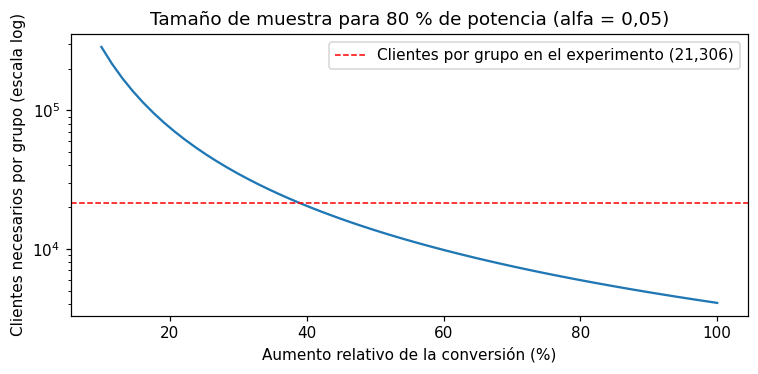

In [14]:
rel = np.linspace(0.10, 1.00, 60)
req = [n_per_group(p0, p0 * (1 + a)) for a in rel]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(100 * rel, req)
ax.axhline(n_ctrl, color="red", linestyle="--", linewidth=1, label=f"Clientes por grupo en el experimento ({n_ctrl:,})")
ax.set_yscale("log")
ax.set_xlabel("Aumento relativo de la conversión (%)")
ax.set_ylabel("Clientes necesarios por grupo (escala log)")
ax.set_title("Tamaño de muestra para 80 % de potencia (alfa = 0,05)")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Conclusiones

- **Prueba global:** hay diferencias entre los tres grupos tanto en conversión (chi-cuadrado = 55,3; p = 1e-12) como en visita (chi-cuadrado = 504,5; p < 1e-100).
- **Conversión (métrica principal):** el email para hombres eleva la conversión de 0,57 % a 1,25 % (+0,68 pp; IC 95 %: 0,50 a 0,86 pp; aumento relativo de 119 %, IC 77 % a 171 %). El email para mujeres la eleva a 0,88 % (+0,31 pp; IC 0,15 a 0,47 pp; +54 %, IC 23 % a 94 %). El de hombres supera al de mujeres en 0,37 pp (IC 0,17 a 0,57 pp). Con el email para hombres, unas 68 compras adicionales por cada 10.000 emails; con el de mujeres, unas 31. Todos los p-valores ajustados por Holm son menores a 0,001.
- **Visita (secundaria):** 10,6 % en el control, 15,1 % con el email para mujeres y 18,3 % con el de hombres. Las diferencias frente al control son de +4,5 pp y +7,7 pp, y entre emails, de 3,1 pp (todas con p < 0,0001). La visita es un paso intermedio: no equivale a ingresos.
- **Gasto por cliente (secundaria):** 0,65 dólares en el control, 1,08 con el email para mujeres y 1,42 con el de hombres. El ingreso incremental por cliente es de 0,77 dólares para hombres (IC bootstrap 0,48 a 1,06) y de 0,42 para mujeres (IC 0,17 a 0,69), es decir, 770 y 424 dólares por cada 1.000 emails. La ventaja del email para hombres sobre el de mujeres es de 0,35 dólares por cliente (IC 0,03 a 0,66; p = 0,03), significativa pero marginal. Los intervalos bootstrap y de Welch casi coinciden, lo que respalda el método a pesar de la asimetría del gasto.
- **Origen del aumento del gasto:** el gasto por cliente es igual a la tasa de conversión por el gasto medio entre compradores, y este último es parecido en los tres grupos (114,00; 113,53 y 121,89 dólares). El mayor gasto por cliente proviene sobre todo de que compra más gente, no de compras más grandes. Esta comparación entre compradores es solo descriptiva, porque ese subconjunto se forma después del tratamiento.
- **Sensibilidad a montos altos:** al limitar el gasto al percentil 90 de los compradores (256,49 dólares), los efectos se mantienen (hombres − control: +0,67; mujeres − control: +0,39; hombres − mujeres: +0,28). El resultado no depende de unas pocas compras grandes. En los tres grupos el gasto máximo es exactamente 499 dólares, lo que sugiere un tope en el registro (no verificado).
- **Comparaciones múltiples:** se aplicó Holm sobre las tres comparaciones de cada métrica. Aplicándolo sobre las nueve comparaciones a la vez, todas siguen siendo significativas al 5 %. Los p-valores que aparecen como 0,0 en las tablas son menores a 0,00001.
- **Potencia:** con 21.306 clientes por grupo y una conversión de control de 0,57 %, el efecto mínimo detectable (80 % de potencia, alfa 0,05) es de 0,22 pp, un aumento relativo de 39 %. Los efectos observados lo superan. En cambio, detectar un aumento relativo de 10 % habría requerido unos 286.000 clientes por grupo, 13 veces más que los disponibles.
- **Limitaciones:** el ingreso es bruto, sin costo de los emails ni margen de los productos; el seguimiento es de solo dos semanas; la muestra son clientes que compraron en los últimos 12 meses; y los dos emails difieren en el contenido (productos para hombres o para mujeres), por lo que no se puede separar el efecto del contenido del efecto de la audiencia. Los intervalos del aumento relativo en conversión son amplios porque se trata de un evento raro.
- **Próximo paso:** el notebook 03 complementa este análisis con un enfoque bayesiano (probabilidad de que un email supere al otro) y explora si el efecto cambia según el tipo de cliente.